# 04 — Frame time, read noise and saturation

The total integration is taken as a series of frames. Short frames pay the read noise many times;
long frames saturate on the residual starlight of a bright host. The ETC exposes both ends.

In this notebook:
1. the frame time and the read noise,
2. the inverse: whole frames versus the continuous solution,
3. `saturation_time()` and bright hosts,
4. the noise budget.

In [1]:
import warnings
import numpy as np
import astropy.units as u
import matplotlib.pyplot as plt
import esc_etc
from esc_etc import Simulation, use_lazuli_style

use_lazuli_style()
warnings.filterwarnings("ignore", module="synphot")

sim = Simulation.from_default(filter="R3", hoststarmag=4.83, hoststar_band="johnson_v",
                              planetdeltamag=20, contrast=1e-8, ppgain=10, separation=0.4)

def frame_for(sim, max_frame=1000 * u.s):
    """Frame time to use: max_frame, or half the saturation time if that is shorter."""
    return min(u.Quantity(max_frame, u.s), 0.5 * sim.saturation_time())


def hours_to_snr(sim, snr=5, max_frame=1000 * u.s):
    """Integration time (hours) to reach snr with the current configuration; NaN above the speckle plateau."""
    return sim.get_int_time_for_snr(snr, frame_for(sim, max_frame))["int_time_continuous"][0].to_value(u.hr)

***
## 1. Frame time

frame     1 s: S/N in 1 h = 0.59
frame    10 s: S/N in 1 h = 1.81


frame   100 s: S/N in 1 h = 4.59
frame  1000 s: S/N in 1 h = 6.71


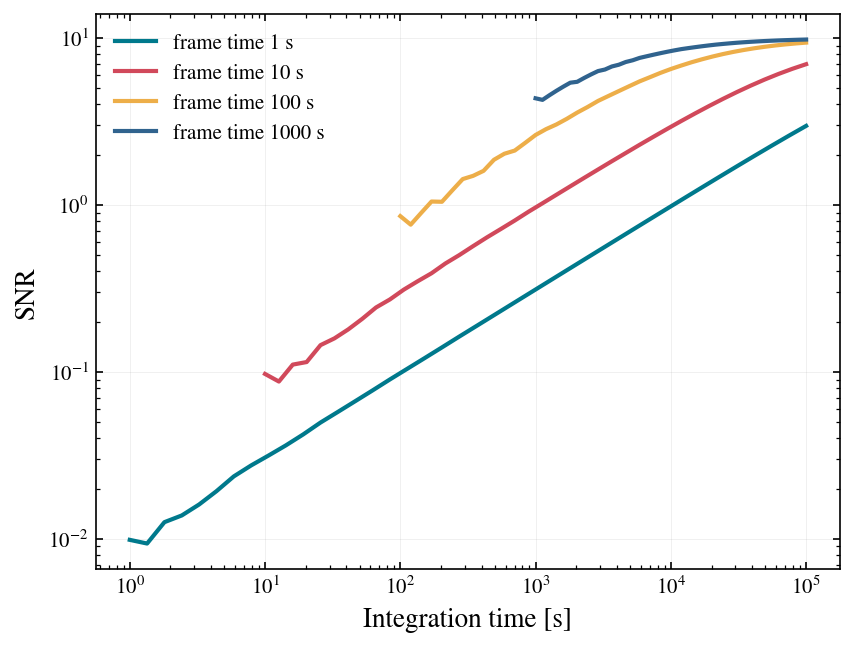

In [2]:
fig, ax = plt.subplots()
for ft in (1, 10, 100, 1000):
    sim.plot_snr_vs_time(frame_time=ft * u.s, ax=ax, label=f"frame time {ft} s")
    print(f"frame {ft:5d} s: S/N in 1 h = {sim.get_snr(3600, ft)['snr']:.2f}")
ax.legend()
plt.show()

With 1.8 e- read noise over 21 pixels, a 1 s frame adds 70 e$^2$ of variance against a planet
rate of 0.08 e-/s: the read noise is everything. At 1000 s it is nothing. For faint planets use
the longest frames the host allows.

***
## 2. Whole frames versus the continuous solution

In [3]:
t = sim.get_int_time_for_snr(5, frame_time=1000)
print(f"S/N 5 with 1000 s frames: {t['int_time_continuous'][0]:.0f} exactly, {t['int_time'][0]:.0f} in whole frames")
t = sim.get_int_time_for_snr(20, frame_time=1000)
print(f"S/N 20 (above the plateau of 10): {t['int_time_continuous'][0]}")

S/N 5 with 1000 s frames: 1425 s exactly, 2000 s in whole frames
S/N 20 (above the plateau of 10): nan s


***
## 3. Saturation and bright hosts

`saturation_time()` is the frame time at which the brightest pixel in the planet aperture fills
80 % of the well; `is_saturated(frame_time)` checks a given frame. Caveat from the esc-etc docs:
only the planet location at dark-hole contrast is modelled, so for a bright host the detector-safe
frame time can be much shorter than this.

> ✏️ **Before you run the next cell:** Sirius is V = -1.4. How long a frame can the ESC take on it before the planet aperture saturates: 1 s, 100 s or an hour? Write your guess down (or put it in the room poll), then run.

In [4]:
print(f"{'V':>5} {'sat. time':>12} {'frame used':>11} {'S/N in 1 h':>10} {'host rate':>14}")
for V in (-1.4, 1.1, 3.0, 5.0, 7.0):
    sim.update(scene__star__mag=V)
    ft = frame_for(sim, 1000 * u.s)
    print(f"{V:5.1f} {sim.saturation_time().to(u.s):12.0f} {ft:11.0f} {sim.get_snr(3600, ft)['snr']:10.2f} {sim.count_rate_components().host:14.3e}")
sim.reset()
print("is_saturated(100 s) for V = 4.83:", bool(sim.is_saturated(100)), "; for a 2 x saturation-time frame:", bool(sim.is_saturated(2 * sim.saturation_time())))

    V    sat. time  frame used S/N in 1 h      host rate


 -1.4         3718 s        1000 s       9.99      5.702e+09 electron / s


  1.1        36895 s        1000 s       9.89      5.702e+08 electron / s


  3.0       204055 s        1000 s       9.36      9.909e+07 electron / s


  5.0      1030102 s        1000 s       6.28      1.570e+07 electron / s


  7.0      2874098 s        1000 s       1.66      2.489e+06 electron / s


is_saturated(100 s) for V = 4.83: False ; for a 2 x saturation-time frame: True


Brighter hosts give higher S/N for the same planet contrast: the planet is brighter too, and the
plateau is the same. The price is the frame time.

***
## 4. The noise budget

Reconstruct `noise_e` from the pieces: planet and background shot noise, read noise per frame,
and the squared speckle floor term. Notice which term grows as $t^2$.

In [5]:
rates = sim.count_rate_components()
s = sim.sensor
for hours in (1, 10):
    t = hours * u.hr
    ft = 100 * u.s
    r = sim.get_snr(t, ft)
    terms = {
        "planet": (rates.source * t).to_value(u.electron),
        "speckle photons": (rates.speckle * t).to_value(u.electron),
        "zodi + exozodi": ((rates.zodi + rates.exozodi) * t).to_value(u.electron),
        "dark": (s.dark_current * s.num_psf_pixels * t).to_value(u.electron),
        "read": (s.read_noise ** 2 * s.num_psf_pixels * (t / ft)).to_value(u.electron),
        "speckle floor (M t)^2": ((r["M"] * t).to_value(u.electron)) ** 2,
    }
    total = sum(terms.values())
    assert abs(total / r["noise_e"] ** 2 - 1) < 0.02, "budget does not add up"
    print(f"--- {hours} h: noise_e^2 = {r['noise_e'] ** 2:.0f}, sum of terms {total:.0f}")
    for k, v in terms.items():
        print(f"    {k:24s} {v:12.0f}  ({v / total:5.1%})")

--- 1 h: noise_e^2 = 4320, sum of terms 4320
    planet                            301  ( 7.0%)
    speckle photons                   301  ( 7.0%)
    zodi + exozodi                     13  ( 0.3%)
    dark                              205  ( 4.7%)
    read                             2591  (60.0%)
    speckle floor (M t)^2             909  (21.0%)


--- 10 h: noise_e^2 = 124983, sum of terms 124983
    planet                           3015  ( 2.4%)
    speckle photons                  3015  ( 2.4%)
    zodi + exozodi                    126  ( 0.1%)
    dark                             2047  ( 1.6%)
    read                            25908  (20.7%)
    speckle floor (M t)^2           90873  (72.7%)


> 🤖 **Ask Jupyter AI:** *Write a function best_frame(sim, max_frame=1000) that returns the longest frame time that keeps sim.is_saturated(frame) False, searching a geometric grid from 1 s to max_frame, and use it to redo the bright-host table above.*
>
> Compare with frame_for: half the saturation time is a simpler rule, but is it the right one when the limitation is the host's own halo rather than the dark hole?

***
## Summary

```python
sim.get_snr(3600, frame_time=1000)                  # read noise once per frame
sim.get_int_time_for_snr(5, 1000)["int_time"]       # whole frames; "int_time_continuous" exact; NaN above the plateau
sim.saturation_time(); sim.is_saturated(100)
frame_for(sim) = min(1000 s, 0.5 * saturation_time)
```

Next: [05 — zodi and exozodi](05_zodi_and_exozodi.ipynb).